# Determinants of Corporate Leverage — Compustat, 2010–2020

**Question.** Which firm characteristics explain how much debt a firm carries relative to its assets, and how much of the variation in leverage do they actually explain?

**Outcome.** Book leverage $= (DLTT + DLC)/AT$, with market leverage $= (DLTT + DLC)/(DLTT + DLC + PRCC\_F \times CSHO)$ as a robustness check.

**Approach.**
1. Build an unbalanced firm-year panel of U.S. non-financial, non-utility firms from Compustat Fundamentals Annual.
2. Construct the target-leverage determinants used by Flannery & Rangan (2006, *JFE*).
3. Estimate pooled OLS, industry + year fixed effects, and firm + year fixed effects with firm-clustered standard errors.
4. Test the OLS assumptions directly: collinearity, heteroskedasticity, within-firm residual dependence, and the bounded outcome.
5. Compare OLS against gradient boosting on a chronological holdout.

The firm-fixed-effects comparison follows Lemmon, Roberts & Zender (2008, *JF*), who show that a persistent firm-specific component dominates the cross-section of leverage.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from linearmodels.panel import PanelOLS

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 50)
os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## 0. Data

Compustat North America Fundamentals Annual (WRDS), fiscal years 2010–2020, using the standard screens `INDFMT = INDL`, `DATAFMT = STD`, `POPSRC = D`, `CONSOL = C`. The screens keep one consolidated, standardized record per firm-year; without them restated and parent-only statements would duplicate firm-years.

Compustat is licensed and is not included in this repository. Set `DATA_SOURCE = "wrds"` to pull it with a WRDS account, or place an export with the same columns at `data/comp_data.csv`.

In [2]:
DATA_SOURCE = "csv"                      # "wrds" or "csv"
CSV_PATH = os.path.join("data", "comp_data.csv")

if DATA_SOURCE == "wrds":
    import wrds
    db = wrds.Connection()
    raw = db.raw_sql('''
        SELECT f.gvkey, f.datadate, f.fyear, f.conm, f.fic, f.curcd, f.sich, c.sic,
               f.at, f.dltt, f.dlc, f.oibdp, f.ppent, f.prcc_f, f.csho, f.ceq, f.lt,
               f.dp, f.xrd, f.sale
        FROM comp.funda AS f
        LEFT JOIN comp.company AS c ON f.gvkey = c.gvkey
        WHERE f.indfmt = 'INDL' AND f.datafmt = 'STD'
          AND f.popsrc = 'D'    AND f.consol  = 'C'
          AND f.fyear BETWEEN 2010 AND 2020
    ''', date_cols=["datadate"])
    os.makedirs("data", exist_ok=True)
    raw.to_csv(CSV_PATH, index=False)
else:
    raw = pd.read_csv(CSV_PATH, parse_dates=["datadate"], dtype={"gvkey": str})

raw.columns = raw.columns.str.lower()
print(raw.shape)

(103373, 25)


## 1. Sample construction

Each filter is logged so the effect of every restriction on the sample is visible before any estimation.

- **Financials (SIC 6000–6999) and utilities (4900–4999)** are excluded because their leverage is set by regulation rather than a free financing choice; for banks, debt is the raw material of the business.
- **Total assets ≥ \$10M** removes shells and micro-caps, where small denominators make every ratio erratic.
- **Leverage in [0, 1]**: debt above total assets indicates deep distress or a data error, a different regime from the one capital-structure theories describe.

In [3]:
log = []

def record(d, label):
    # Log the sample size after each restriction
    log.append({"Step": label, "Firm-years": len(d), "Firms": d["gvkey"].nunique()})
    return d

df = raw.copy()
df["gvkey"] = df["gvkey"].astype(str).str.zfill(6)
df = record(df, "Raw download (FY2010–2020, INDL/STD/D/C screens)")

# One record per firm-year; keep the latest datadate when a firm changed fiscal year-end
df = df[df["fyear"].between(2010, 2020)]
df = df.sort_values(["gvkey", "fyear", "datadate"]).drop_duplicates(["gvkey", "fyear"], keep="last")
df = record(df, "Unique firm-years")

# Historical SIC (sich) reflects the industry in that year; fall back to the header SIC
df["sic_code"] = pd.to_numeric(df["sich"], errors="coerce").fillna(pd.to_numeric(df["sic"], errors="coerce"))
df = df[df["sic_code"].notna()]
df = record(df, "Non-missing SIC code")

df = df[~df["sic_code"].between(6000, 6999)]
df = record(df, "Exclude financials (SIC 6000–6999)")
df = df[~df["sic_code"].between(4900, 4999)]
df = record(df, "Exclude utilities (SIC 4900–4999)")

MIN_ASSETS = 10  # $ millions
df = df[df["at"] > 0]
df = record(df, "Total assets > 0")
df = df[df["at"] >= MIN_ASSETS]
df = record(df, f"Total assets ≥ ${MIN_ASSETS}M")

df = df[df["dltt"].notna() & df["dlc"].notna()]
df = record(df, "Non-missing DLTT and DLC")
df["book_lev"] = (df["dltt"] + df["dlc"]) / df["at"]
df = df[df["book_lev"].between(0, 1)]
df = record(df, "0 ≤ book leverage ≤ 1")

### Determinants

| Variable | Construction | Expected sign and rationale |
|---|---|---|
| `profitability` | OIBDP / AT | − pecking order (Myers & Majluf 1984): profitable firms fund internally. Trade-off theory predicts +. |
| `tangibility` | PPENT / AT | + collateral lowers lenders' loss given default. |
| `size` | ln(AT) | + larger firms are more diversified and default less. |
| `mtb` | (AT − CEQ + PRCC_F × CSHO) / AT | − growth options are lost in distress (Myers 1977). |
| `dep` | DP / AT | − non-debt tax shield substitutes for interest deductions (DeAngelo & Masulis 1980). |
| `rd` | XRD / AT, missing set to 0 | − intangible assets support little debt (Titman 1984). |
| `rd_missing` | 1 if XRD is missing | Separates non-reporters from true zero-R&D firms (Flannery & Rangan 2006). |
| `ind_median` | Median book leverage by 2-digit SIC × year | + firms with similar business risk choose similar debt ratios. |

Profitability uses OIBDP, which is measured before interest. Net income falls mechanically as debt rises, which would build a negative leverage–profitability relationship into the variable itself.

Continuous ratios are winsorized at the 1st and 99th percentiles. OLS minimizes squared residuals, so a handful of extreme ratios from small denominators would otherwise dominate the fit; winsorizing caps them without dropping the firm.

In [4]:
df["profitability"] = df["oibdp"] / df["at"]
df["tangibility"]   = df["ppent"] / df["at"]
df["size"]          = np.log(df["at"])
df["mtb"]           = (df["at"] - df["ceq"] + df["prcc_f"] * df["csho"]) / df["at"]
df["dep"]           = df["dp"] / df["at"]
df["rd_missing"]    = df["xrd"].isna().astype(int)
df["rd"]            = df["xrd"].fillna(0) / df["at"]
df["mkt_lev"]       = (df["dltt"] + df["dlc"]) / (df["dltt"] + df["dlc"] + df["prcc_f"] * df["csho"])
df["sic2"]          = (df["sic_code"] // 100).astype(int)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["profitability", "tangibility", "size", "mtb", "dep", "rd"])
df = record(df, "Non-missing determinants")

def winsorize(s, lo=0.01, hi=0.99):
    # Cap at the 1st/99th percentiles rather than dropping observations
    return s.clip(s.quantile(lo), s.quantile(hi))

for v in ["profitability", "mtb", "dep", "rd", "size", "mkt_lev"]:
    df[v] = winsorize(df[v])

# Industry benchmark: median book leverage within 2-digit SIC and year
df["ind_median"] = df.groupby(["sic2", "fyear"])["book_lev"].transform("median")

X_VARS = ["profitability", "tangibility", "size", "mtb", "dep", "rd", "rd_missing", "ind_median"]
Y = "book_lev"

cleaning_log = pd.DataFrame(log)
cleaning_log.to_csv("tables/table1_cleaning_log.csv", index=False)
cleaning_log

,Step,Firm-years,Firms
0,"Raw download (FY2010–2020, INDL/STD/D/C screens)",103373,16110
1,Unique firm-years,102408,16050
2,Non-missing SIC code,102408,16050
3,Exclude financials (SIC 6000–6999),62518,10092
4,Exclude utilities (SIC 4900–4999),58939,9680
5,Total assets > 0,56384,9381
6,Total assets ≥ $10M,48094,7993
7,Non-missing DLTT and DLC,47889,7988
8,0 ≤ book leverage ≤ 1,46945,7912
9,Non-missing determinants,41714,6937


In [5]:
# Panel structure: unbalanced because firms enter (IPOs) and exit (delistings, M&A)
yrs = df.groupby("gvkey")["fyear"].nunique()
print(f"Firms: {df.gvkey.nunique():,} | Firm-years: {len(df):,} | Years: {df.fyear.min()}–{df.fyear.max()}")
print(f"Years per firm: mean {yrs.mean():.1f}, median {yrs.median():.0f}; "
      f"firms observed all 11 years: {(yrs == 11).mean():.1%}")
print(f"Share of firm-years with zero debt: {(df.book_lev == 0).mean():.1%}")
print(f"Share of firm-years with missing R&D: {df.rd_missing.mean():.1%}")
df.groupby("fyear").size().rename("Firm-years").to_frame().T

Firms: 6,937 | Firm-years: 41,714 | Years: 2010–2020
Years per firm: mean 6.0, median 6; firms observed all 11 years: 23.2%
Share of firm-years with zero debt: 17.1%
Share of firm-years with missing R&D: 37.4%


fyear,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
Firm-years,3929,3858,3794,3841,3930,3846,3726,3711,3745,3743,3591


In [6]:
def summary_table(d, cols):
    s = d[cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
    s = s[["count", "mean", "std", "1%", "25%", "50%", "75%", "99%"]]
    s.columns = ["N", "Mean", "SD", "P1", "P25", "Median", "P75", "P99"]
    s["N"] = s["N"].astype(int)
    return s

table2 = summary_table(df, ["book_lev", "mkt_lev"] + X_VARS)
table2.to_csv("tables/table2_summary_stats.csv")
table2

,N,Mean,SD,P1,P25,Median,P75,P99
book_lev,41714,0.231,0.218,0.000,0.021,0.193,0.368,0.859
mkt_lev,41714,0.215,0.235,0.000,0.012,0.138,0.335,0.912
profitability,41714,0.019,0.242,-1.075,-0.008,0.088,0.144,0.373
tangibility,41714,0.252,0.254,0.000,0.056,0.153,0.378,0.928
size,41714,6.458,2.228,2.450,4.745,6.380,8.009,11.802
mtb,41714,2.141,1.727,0.463,1.123,1.552,2.452,10.447
dep,41714,0.040,0.032,0.000,0.019,0.034,0.053,0.170
rd,41714,0.063,0.128,0.000,0.000,0.004,0.067,0.723
rd_missing,41714,0.374,0.484,0.000,0.000,0.000,1.000,1.000
ind_median,41714,0.192,0.117,0.000,0.100,0.162,0.273,0.514


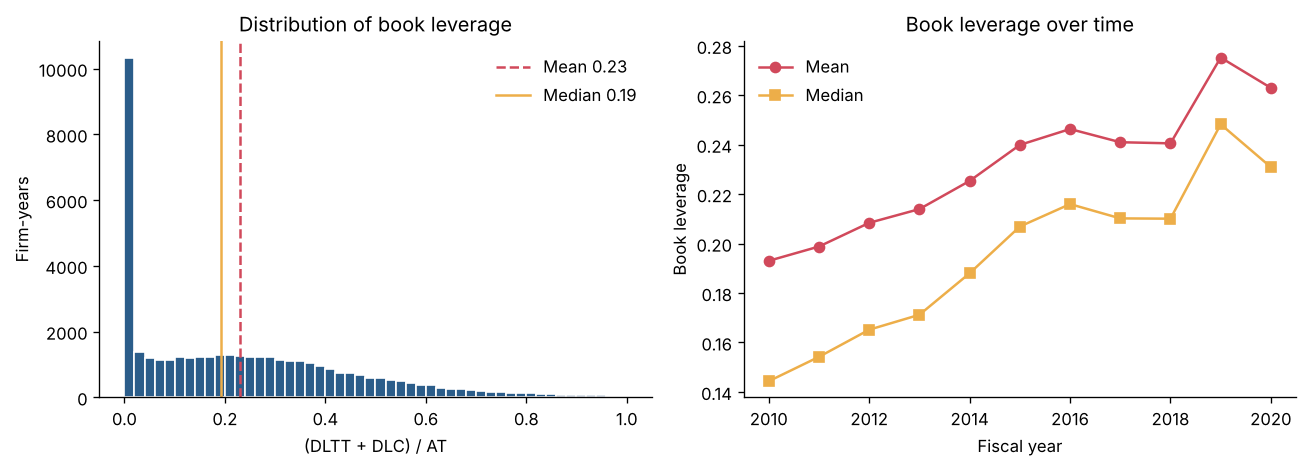

In [7]:
# Distribution of the outcome: bounded in [0, 1], a mass at zero, right-skewed
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["book_lev"], bins=50, color="#2b5d8a", edgecolor="white")
ax[0].axvline(df["book_lev"].mean(),   color="#d1495b", ls="--", label=f"Mean {df.book_lev.mean():.2f}")
ax[0].axvline(df["book_lev"].median(), color="#edae49", ls="-",  label=f"Median {df.book_lev.median():.2f}")
ax[0].set(title="Distribution of book leverage", xlabel="(DLTT + DLC) / AT", ylabel="Firm-years")
ax[0].legend(frameon=False)

by_year = df.groupby("fyear")["book_lev"].agg(["mean", "median"])
ax[1].plot(by_year.index, by_year["mean"],   marker="o", label="Mean",   color="#d1495b")
ax[1].plot(by_year.index, by_year["median"], marker="s", label="Median", color="#edae49")
ax[1].set(title="Book leverage over time", xlabel="Fiscal year", ylabel="Book leverage")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/fig1_leverage_distribution.png", bbox_inches="tight"); plt.show()

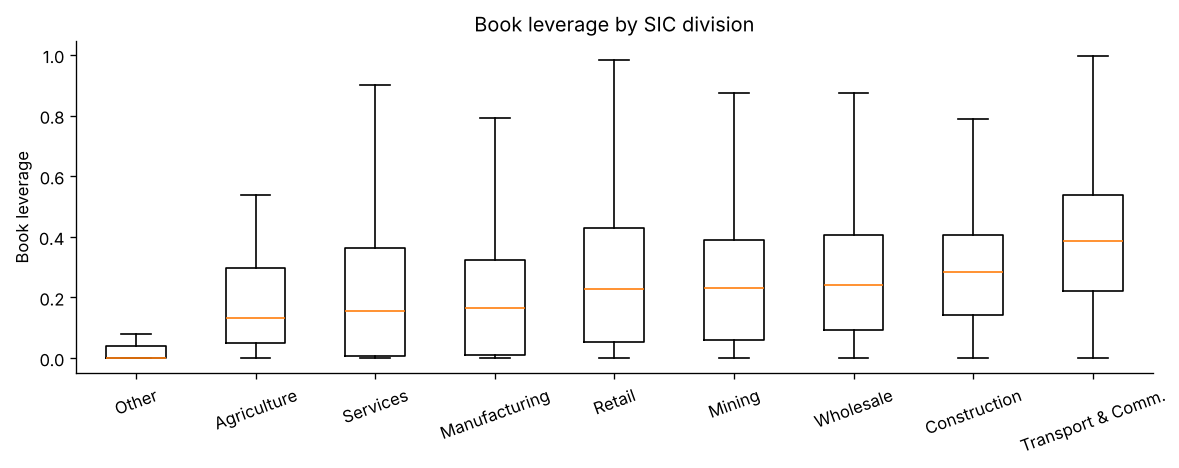

In [8]:
# Large, persistent industry differences motivate industry and firm fixed effects
def division(s):
    if s < 1000: return "Agriculture"
    if s < 1500: return "Mining"
    if s < 1800: return "Construction"
    if s < 4000: return "Manufacturing"
    if s < 5000: return "Transport & Comm."
    if s < 5200: return "Wholesale"
    if s < 6000: return "Retail"
    if s < 9000: return "Services"
    return "Other"

df["division"] = df["sic_code"].apply(division)
order = df.groupby("division")["book_lev"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df.loc[df.division == d, "book_lev"] for d in order], tick_labels=order, showfliers=False)
ax.set(title="Book leverage by SIC division", ylabel="Book leverage")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("figures/fig2_leverage_by_industry.png", bbox_inches="tight"); plt.show()

## 2. Correlations and collinearity

Pairwise correlations with leverage are univariate and can differ in sign from regression coefficients, which hold the other predictors fixed. Spearman correlations are reported alongside Pearson as a check against outliers and nonlinearity.

Collinearity among predictors is measured with the variance inflation factor, $\text{VIF}_j = 1/(1 - R_j^2)$, where $R_j^2$ comes from regressing predictor $j$ on the others. Collinearity inflates the variance of $\hat\beta_j$ but does not bias it.

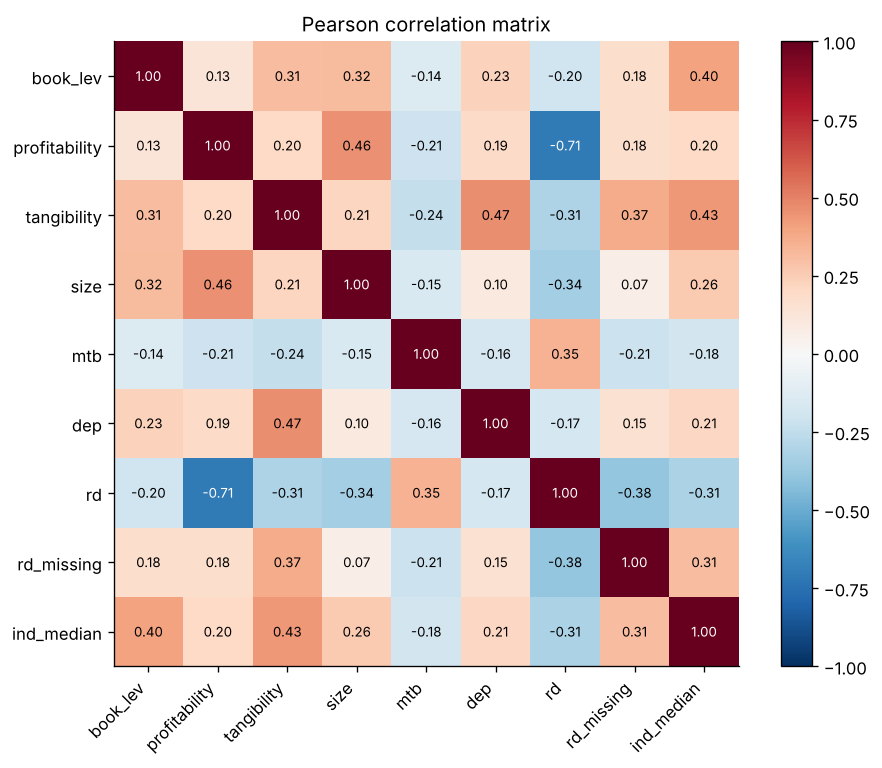

,Pearson,Spearman
profitability,0.129,0.162
tangibility,0.305,0.350
size,0.318,0.403
mtb,-0.136,-0.149
dep,0.228,0.281
rd,-0.198,-0.291
rd_missing,0.180,0.182
ind_median,0.403,0.402


In [9]:
corr = df[[Y] + X_VARS].corr()
corr.to_csv("tables/table3_correlations.csv")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
plt.colorbar(im, fraction=0.046); ax.set_title("Pearson correlation matrix")
plt.tight_layout(); plt.savefig("figures/fig3_correlations.png", bbox_inches="tight"); plt.show()

pd.DataFrame({"Pearson":  df[X_VARS].corrwith(df[Y]),
              "Spearman": df[X_VARS].corrwith(df[Y], method="spearman")})

In [10]:
Xc = sm.add_constant(df[X_VARS])
vif = pd.DataFrame({"VIF": [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]},
                   index=X_VARS).sort_values("VIF", ascending=False)
vif.to_csv("tables/table4_vif.csv")
vif

,VIF
rd,2.551
profitability,2.347
tangibility,1.659
size,1.344
ind_median,1.342
rd_missing,1.336
dep,1.311
mtb,1.177


## 3. Linear model

$$
\text{BookLev}_{it} = \beta_0 + \beta_1\,\text{Prof}_{it} + \beta_2\,\text{Tang}_{it} + \beta_3\,\text{Size}_{it} + \beta_4\,\text{MTB}_{it} + \beta_5\,\text{Dep}_{it} + \beta_6\,\text{RD}_{it} + \beta_7\,\text{RDmiss}_{it} + \beta_8\,\text{IndMed}_{jt} + \varepsilon_{it}
$$

with $i$ = firm, $t$ = fiscal year, $j$ = 2-digit SIC industry. Unobserved, time-invariant firm traits (risk appetite, ownership, credit history) that correlate with the regressors would bias pooled OLS, so the model is also estimated with fixed effects:

$$
\text{BookLev}_{it} = \alpha_i + \lambda_t + x_{it}'\beta + \varepsilon_{it}
$$

| Model | Fixed effects | Variation identifying β |
|---|---|---|
| (1) Pooled OLS | none | Across firms and over time |
| (2) Industry + Year FE | 2-digit SIC, year | Between firms in the same industry and year |
| (3) Firm + Year FE | firm, year | Within a firm over time |

`ind_median` enters only model (1): industry dummies replace it in (2), and it is absorbed by firm effects in (3).

Standard errors are clustered by firm in all models. The same firm appears up to 11 times with positively correlated residuals, so classical standard errors would treat dependent observations as independent evidence (Petersen 2009).

In [11]:
panel = df.set_index(["gvkey", "fyear"]).sort_index()
X_FE = [v for v in X_VARS if v != "ind_median"]

m1 = PanelOLS(panel[Y], sm.add_constant(panel[X_VARS])).fit(cov_type="clustered", cluster_entity=True)
m2 = PanelOLS(panel[Y], sm.add_constant(panel[X_FE]), time_effects=True,
              other_effects=panel[["sic2"]]).fit(cov_type="clustered", cluster_entity=True)
m3 = PanelOLS(panel[Y], sm.add_constant(panel[X_FE]), entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
print(m1.summary.tables[1])

                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const            -0.0704     0.0083    -8.4661     0.0000     -0.0867     -0.0541
profitability    -0.1125     0.0111    -10.121     0.0000     -0.1343     -0.0907
tangibility       0.0589     0.0120     4.8888     0.0000      0.0353      0.0825
size              0.0247     0.0011     22.104     0.0000      0.0225      0.0269
mtb              -0.0013     0.0011    -1.2358     0.2165     -0.0034      0.0008
dep               0.8218     0.0785     10.475     0.0000      0.6680      0.9756
rd               -0.0924     0.0215    -4.2913     0.0000     -0.1346     -0.0502
rd_missing        0.0145     0.0054     2.7050     0.0068      0.0040      0.0251
ind_median        0.5144     0.0222     23.174     0.0000      0.4709      0.5579


In [12]:
def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .1 else ""

def results_table(models, names, fe_rows):
    rows = []
    for v in X_VARS + ["const"]:
        coef_row, se_row = {"": v}, {"": ""}
        for m, n in zip(models, names):
            if v in m.params.index:
                coef_row[n] = f"{m.params[v]:.3f}{stars(m.pvalues[v])}"
                se_row[n]   = f"({m.std_errors[v]:.3f})"
            else:
                coef_row[n], se_row[n] = "", ""
        rows += [coef_row, se_row]
    for label, vals in fe_rows.items():
        rows.append({"": label, **dict(zip(names, vals))})
    rows.append({"": "Observations", **{n: f"{int(m.nobs):,}" for m, n in zip(models, names)}})
    rows.append({"": "R² (incl. fixed effects)",
                 **{n: f"{getattr(m, 'rsquared_inclusive', m.rsquared):.3f}" for m, n in zip(models, names)}})
    rows.append({"": "Within R²",
                 **{n: (f"{m.rsquared_within:.3f}" if i == 2 else "") for i, (m, n) in enumerate(zip(models, names))}})
    return pd.DataFrame(rows).set_index("")

names = ["(1) Pooled OLS", "(2) Industry+Year FE", "(3) Firm+Year FE"]
fe_rows = {"Industry FE": ["No", "Yes", "Absorbed"], "Year FE": ["No", "Yes", "Yes"], "Firm FE": ["No", "No", "Yes"]}
table5 = results_table([m1, m2, m3], names, fe_rows)
table5.to_csv("tables/table5_ols_book_leverage.csv")
print("Dependent variable: book leverage. Firm-clustered SEs in parentheses. *** p<.01, ** p<.05, * p<.1")
table5

Dependent variable: book leverage. Firm-clustered SEs in parentheses. *** p<.01, ** p<.05, * p<.1


,(1) Pooled OLS,(2) Industry+Year FE,(3) Firm+Year FE
,,,
profitability,-0.113***,-0.126***,-0.135***
,(0.011),(0.011),(0.013)
tangibility,0.059***,0.161***,0.240***
,(0.012),(0.015),(0.022)
size,0.025***,0.026***,0.042***
,(0.001),(0.001),(0.004)
mtb,-0.001,-0.002**,-0.002
,(0.001),(0.001),(0.001)
dep,0.822***,0.899***,0.617***


### Economic magnitudes

With over 40,000 observations nearly every coefficient is statistically significant, so factors are ranked by economic size: the change in leverage from a one-standard-deviation increase in each predictor, $\hat\beta_k \times SD(x_k)$. This puts log assets and ratios on a common scale.

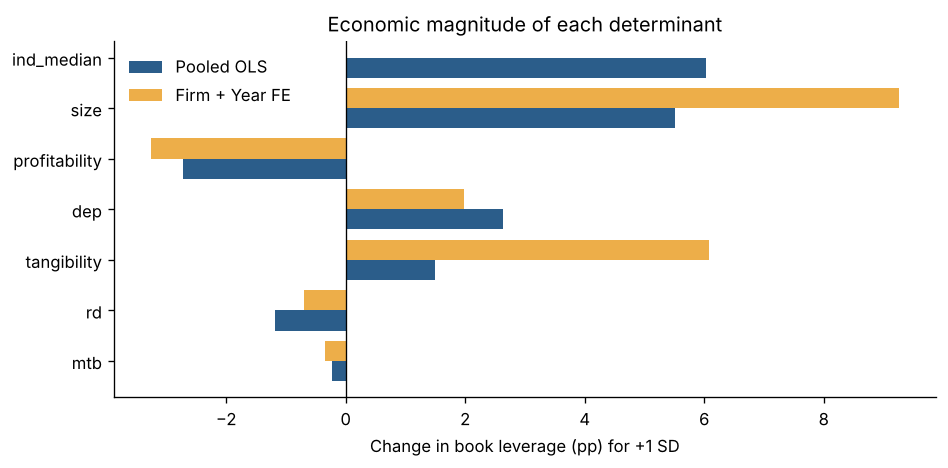

,"1-SD effect, pooled (pp)","1-SD effect, firm FE (pp)"
mtb,-0.225,-0.346
rd,-1.184,-0.703
tangibility,1.493,6.075
dep,2.639,1.982
profitability,-2.722,-3.257
size,5.509,9.253
ind_median,6.033,NaN


In [13]:
sd = df[X_VARS].std()
econ = pd.DataFrame({
    "1-SD effect, pooled (pp)":  m1.params[X_VARS] * sd * 100,
    "1-SD effect, firm FE (pp)": m3.params.reindex(X_VARS) * sd * 100,
}).drop(index="rd_missing")  # a dummy: its coefficient is already the 0→1 effect
econ = econ.reindex(econ["1-SD effect, pooled (pp)"].abs().sort_values().index)
econ.to_csv("tables/table6_economic_magnitudes.csv")

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(econ))
ax.barh(y - 0.2, econ.iloc[:, 0], 0.4, label="Pooled OLS", color="#2b5d8a")
ax.barh(y + 0.2, econ.iloc[:, 1], 0.4, label="Firm + Year FE", color="#edae49")
ax.set_yticks(y); ax.set_yticklabels(econ.index); ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Change in book leverage (pp) for +1 SD", title="Economic magnitude of each determinant")
ax.legend(frameon=False); plt.tight_layout()
plt.savefig("figures/fig4_economic_magnitudes.png", bbox_inches="tight"); plt.show()
econ

## 4. Testing the OLS assumptions

| Assumption | Check |
|---|---|
| Linearity with a bounded outcome | Share of fitted values outside [0, 1]; mass at zero |
| Homoskedasticity | Breusch–Pagan test; robust vs. classical standard errors |
| Independence across observations | Same-firm residual autocorrelation, Durbin–Watson, clustered vs. classical standard errors |
| No perfect collinearity | VIFs (Section 2) |
| Normal errors (not required with large N) | Residual skewness |

,Value
Breusch–Pagan LM statistic,1125.710
Breusch–Pagan p-value,0.000
"Residual autocorrelation (same firm, t vs t−1)",0.851
Durbin–Watson (firm-sorted),0.608
"Share of fitted values outside [0,1]",0.000
Share of firm-years with zero debt,0.171
Residual skewness,1.039


,Robust (HC1) / classical,Clustered / classical
const,0.942,2.096
profitability,1.182,1.894
tangibility,1.125,2.559
size,0.961,2.320
mtb,1.026,1.811
dep,1.190,2.375
rd,1.128,1.863
rd_missing,1.035,2.427
ind_median,1.072,2.425


,t (classical),t (firm-clustered)
const,-17.745,-8.466
profitability,-19.168,-10.121
tangibility,12.507,4.888
size,51.269,22.103
mtb,-2.238,-1.236
dep,24.872,10.474
rd,-7.995,-4.291
rd_missing,6.565,2.705
ind_median,56.188,23.172


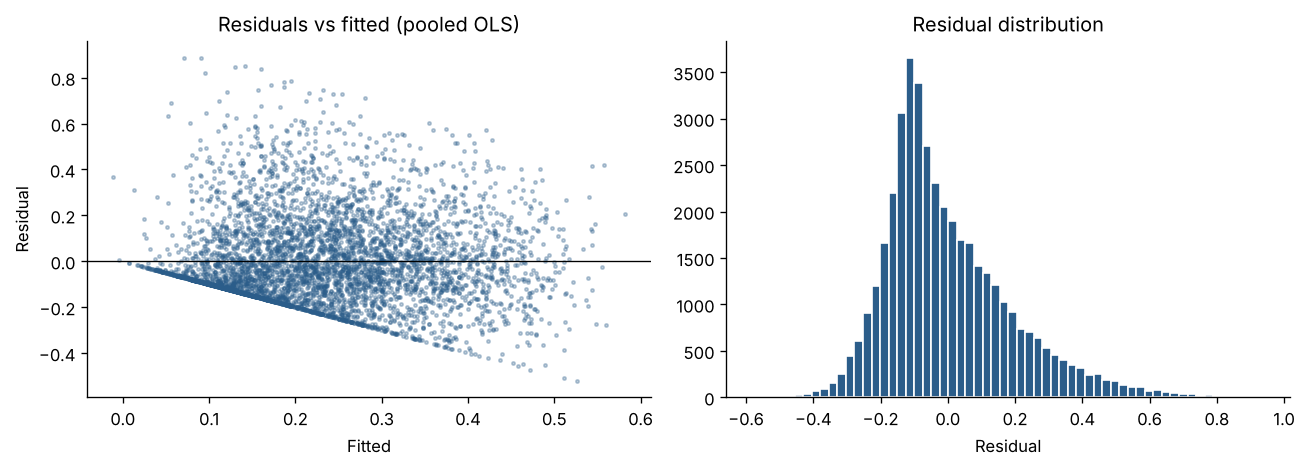

In [14]:
# Pooled OLS in statsmodels to obtain classical, robust, and clustered SEs on the same fit
ols    = sm.OLS(df[Y], sm.add_constant(df[X_VARS])).fit()
ols_hc = sm.OLS(df[Y], sm.add_constant(df[X_VARS])).fit(cov_type="HC1")
ols_cl = sm.OLS(df[Y], sm.add_constant(df[X_VARS])).fit(cov_type="cluster", cov_kwds={"groups": df["gvkey"]})

bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)

# Within-firm dependence: correlation of a firm's residual with its own residual one year earlier
res = df[["gvkey", "fyear"]].assign(e=ols.resid.values).sort_values(["gvkey", "fyear"])
res["e_lag"] = res.groupby("gvkey")["e"].shift()
rho = res[["e", "e_lag"]].dropna().corr().iloc[0, 1]
dw = durbin_watson(res["e"])

outside = ((ols.fittedvalues < 0) | (ols.fittedvalues > 1)).mean()

diag = pd.DataFrame({"Value": [bp_stat, bp_p, rho, dw, outside, (df[Y] == 0).mean(), ols.resid.skew()]},
    index=["Breusch–Pagan LM statistic", "Breusch–Pagan p-value",
           "Residual autocorrelation (same firm, t vs t−1)", "Durbin–Watson (firm-sorted)",
           "Share of fitted values outside [0,1]", "Share of firm-years with zero debt", "Residual skewness"])
diag.to_csv("tables/table7_diagnostics.csv")

se_ratio = pd.DataFrame({"Robust (HC1) / classical": ols_hc.bse / ols.bse,
                         "Clustered / classical":    ols_cl.bse / ols.bse})
se_ratio.to_csv("tables/table8_se_ratios.csv")
t_compare = pd.DataFrame({"t (classical)": ols.tvalues, "t (firm-clustered)": ols_cl.tvalues})

display(diag); display(se_ratio); display(t_compare)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
samp = np.random.default_rng(0).choice(len(ols.resid), size=min(5000, len(ols.resid)), replace=False)
ax[0].scatter(ols.fittedvalues.iloc[samp], ols.resid.iloc[samp], s=4, alpha=0.3, color="#2b5d8a")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set(title="Residuals vs fitted (pooled OLS)", xlabel="Fitted", ylabel="Residual")
ax[1].hist(ols.resid, bins=60, color="#2b5d8a", edgecolor="white")
ax[1].set(title="Residual distribution", xlabel="Residual")
plt.tight_layout(); plt.savefig("figures/fig5_residual_diagnostics.png", bbox_inches="tight"); plt.show()

## 5. Robustness: market leverage

Market leverage values equity at the share price, so it responds to prices even when a firm issues no debt. Market-to-book is expected to become strongly negative, partly mechanically, since market equity enters both the regressor and the denominator of the outcome.

In [15]:
pm = panel.dropna(subset=["mkt_lev"])
mk1 = PanelOLS(pm["mkt_lev"], sm.add_constant(pm[X_VARS])).fit(cov_type="clustered", cluster_entity=True)
mk2 = PanelOLS(pm["mkt_lev"], sm.add_constant(pm[X_FE]), time_effects=True,
               other_effects=pm[["sic2"]]).fit(cov_type="clustered", cluster_entity=True)
mk3 = PanelOLS(pm["mkt_lev"], sm.add_constant(pm[X_FE]), entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
table9 = results_table([mk1, mk2, mk3], names, fe_rows)
table9.to_csv("tables/table9_ols_market_leverage.csv")
print("Dependent variable: market leverage. Firm-clustered SEs in parentheses.")
table9

Dependent variable: market leverage. Firm-clustered SEs in parentheses.


,(1) Pooled OLS,(2) Industry+Year FE,(3) Firm+Year FE
,,,
profitability,-0.178***,-0.198***,-0.193***
,(0.010),(0.010),(0.012)
tangibility,0.105***,0.200***,0.256***
,(0.013),(0.016),(0.022)
size,0.020***,0.021***,0.042***
,(0.001),(0.001),(0.004)
mtb,-0.038***,-0.036***,-0.025***
,(0.001),(0.001),(0.001)
dep,0.749***,0.772***,0.887***


## 6. Out-of-sample comparison: OLS vs. gradient boosting

Models are trained on 2010–2017 and evaluated on 2018–2020. The split is chronological: a random split would let a model learn from a firm's later years and "predict" its earlier ones. `ind_median` is excluded because it is built from same-year leverage of the firm and its peers, which would leak the target into the features.

Gradient-boosted trees can capture nonlinearities and interactions that OLS cannot. Permutation importance (the drop in test R² when a feature is shuffled) gives a model-agnostic ranking to compare with the economic magnitudes above.

In [16]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import permutation_importance

feats = X_FE
train, test = df[df.fyear <= 2017], df[df.fyear >= 2018]
models = {
    "OLS": LinearRegression(),
    "Gradient boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                       min_samples_leaf=50, random_state=0),
}
oos = {}
for name, mdl in models.items():
    mdl.fit(train[feats], train[Y])
    pred = mdl.predict(test[feats])
    oos[name] = {"Train R²": r2_score(train[Y], mdl.predict(train[feats])),
                 "Test R² (2018–20)": r2_score(test[Y], pred),
                 "Test RMSE": mean_squared_error(test[Y], pred) ** 0.5}
oos = pd.DataFrame(oos).T
oos.to_csv("tables/table10_out_of_sample.csv")
display(oos)

pi = permutation_importance(models["Gradient boosting"], test[feats], test[Y], n_repeats=5, random_state=0)
perm = pd.Series(pi.importances_mean, index=feats).sort_values(ascending=False) \
         .rename("Permutation importance (drop in test R²)").to_frame()
perm.to_csv("tables/table11_permutation_importance.csv")
perm

,Train R²,Test R² (2018–20),Test RMSE
OLS,0.186,0.158,0.204
Gradient boosting,0.433,0.267,0.190


,Permutation importance (drop in test R²)
size,0.195
tangibility,0.113
dep,0.106
rd,0.094
mtb,0.088
profitability,0.070
rd_missing,0.011


## 7. Conclusions

See the [README](README.md) for the full discussion. In brief:

- **Size is the strongest firm-level determinant** of leverage across pooled OLS, firm fixed effects, and gradient-boosting importance. Tangibility is second and strengthens sharply within firms.
- **Profitability is negative in every specification**, including within firms, despite a positive univariate correlation. This supports the pecking-order theory over the trade-off theory.
- **Leverage is mostly a persistent firm-specific trait.** Firm fixed effects raise R² from about 0.24 to 0.80, while within-firm R² is about 0.11, consistent with Lemmon, Roberts & Zender (2008).
- **Inference requires firm clustering.** Same-firm residuals are highly autocorrelated, clustered standard errors are roughly two to two-and-a-half times classical ones, and market-to-book loses significance once errors are clustered.
- **The estimates are conditional associations, not causal effects**, given omitted firm traits and the joint determination of leverage, investment, and asset structure.